# Homework 3 — Classification — ML Zoomcamp 2026 cohort

Predict `converted` (did the lead sign up?) on the 2026 lead-scoring dataset. Questions: `homework3_2026.md`.

**Submit at:** https://courses.datatalks.club/ml-zoomcamp-2026/homework/hw03

## Setup and dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mutual_info_score, accuracy_score

%matplotlib inline

df_raw = pd.read_csv('course_lead_scoring_2026.csv')
df = df_raw.copy()
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Data preparation

Check for missing values. Categorical columns: fill with `'NA'`. Numerical columns: fill with `0.0`.

In [ ]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
import pandas as pd

target = 'converted'

# 1) The target must be numeric (0/1) and complete before anything else
assert pd.api.types.is_numeric_dtype(df[target]), f"{target} is not numeric: {df[target].dtype}"
assert df[target].isna().sum() == 0, f"{target} has missing values"
assert set(df[target].unique()) <= {0, 1}, f"{target} is not 0/1: {df[target].unique()}"

# 2) Build the feature lists from the dtypes (target excluded)
categorical = df.select_dtypes(include=['object', 'string']).columns.tolist()
numerical = df.select_dtypes(include='number').columns.drop(target).tolist()

print('categorical:', categorical)
print('numerical:  ', numerical)

# 3) Fill the gaps: categorical -> 'NA', numerical -> 0.0
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

# 4) Check
assert df.isna().sum().sum() == 0
df.isna().sum()

categorical: ['lead_source', 'industry', 'employment_status', 'location']
numerical:   ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

## Q1. Mode of `industry`

*(NA / technology / healthcare / retail)*

In [5]:
df.industry.mode()

0    technology
Name: industry, dtype: str

In [ ]:
df.industry.value_counts(dropna=False)

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64

## Q2. Biggest correlation among the numerical features

Only consider these pairs: *(interaction_count & lead_score / number_of_courses_viewed & lead_score / number_of_courses_viewed & interaction_count / annual_income & interaction_count)*

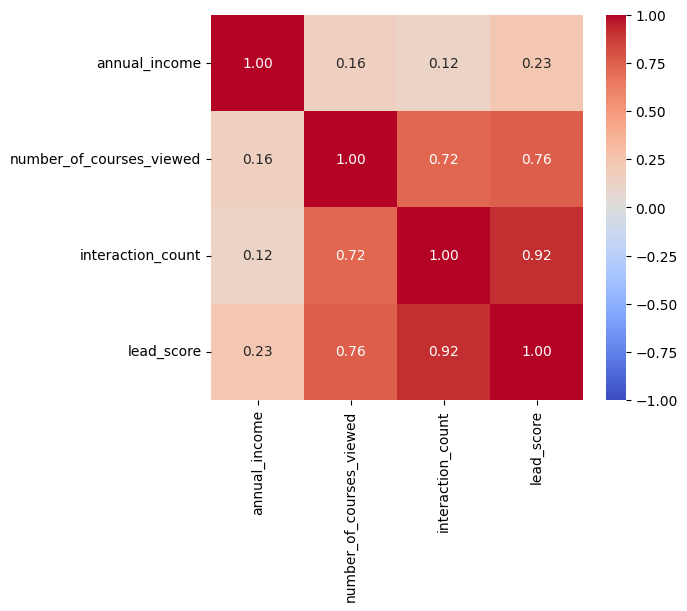

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df[numerical].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

## Split — 60/20/20

Pull out `y_train`, `y_val`, `y_test` and remove `converted` from the three dataframes.

In [ ]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)


## Q3. Mutual information with `converted`

Categorical variables only, **training set only**, `round(score, 2)`. *(industry / location / lead_source / employment_status)*

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

# take the targets out first, then remove them from the dataframes
y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

del df_train[target]
del df_val[target]
del df_test[target]

# mutual information of each categorical column with the target
mi = df_train[categorical].apply(lambda col: mutual_info_score(col, y_train))
mi.round(2).sort_values(ascending=False)

lead_source          0.03
employment_status    0.02
industry             0.00
location             0.00
dtype: float64

## Q4. Logistic regression — validation accuracy

One-hot encode the categoricals (lesson 3.8, `DictVectorizer`), fit on train, score on validation, round to 2 decimals. Use exactly:

```python
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
```

*(0.55 / 0.65 / 0.75 / 0.85)*

In [16]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

features = categorical + numerical

# 1) dataframe -> list of dicts (one dict per row)
train_dicts = df_train[features].to_dict(orient='records')
val_dicts = df_val[features].to_dict(orient='records')

# 2) one-hot encoding: fit on train, only transform validation
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

# 3) train and evaluate
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_val)
accuracy = (y_pred == y_val).mean()
round(accuracy, 3)

np.float64(0.645)

## Q5. Feature elimination — least useful feature

Same features and parameters as Q4, **no rounding**. Drop one feature at a time, retrain, and record `original_accuracy − accuracy_without_feature`. Which has the smallest difference? *(lead_source / number_of_courses_viewed / interaction_count)*

In [17]:
def train_and_score(feature_list):
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(df_train[feature_list].to_dict(orient='records'))
    X_val = dv.transform(df_val[feature_list].to_dict(orient='records'))

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    return (model.predict(X_val) == y_val).mean()

# accuracy with all features
base_accuracy = train_and_score(features)
print(base_accuracy)

0.645


In [18]:
results = []

for feature in features:
    subset = [f for f in features if f != feature]   # all features except this one
    acc = train_and_score(subset)
    results.append((feature, acc, base_accuracy - acc))

pd.DataFrame(results, columns=['feature', 'accuracy_without', 'difference']) \
    .sort_values('difference')

,feature,accuracy_without,difference
4,annual_income,0.724,-0.079
1,industry,0.645,0.000
2,employment_status,0.645,0.000
3,location,0.645,0.000
7,lead_score,0.644,0.001
5,number_of_courses_viewed,0.643,0.002
0,lead_source,0.642,0.003
6,interaction_count,0.601,0.044


## Q6. Regularisation strength `C`

`C` in `[0.000001, 0.00001, 0.0001, 0.001]`, all features as in Q4, accuracy rounded to **3** decimals, smallest `C` wins ties.

In [20]:
# encode once (same as Q4)
features = categorical + numerical
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))

# one model per value of C
for C in [0.000001, 0.00001, 0.0001, 0.001]:
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    accuracy = (model.predict(X_val) == y_val).mean()
    print(C, round(accuracy, 3))

1e-06 0.598
1e-05 0.598
0.0001 0.613
0.001 0.645
